# Audio — Deteksi Event Suara (kapan terjadi + apa labelnya)
**Kapan dipakai:** rekaman panjang berisi beberapa kejadian (kata perintah, klakson, batuk,
tembakan). Jawaban per event: `path`, `onset` (detik mulai), `offset` (detik selesai), `label`.

**Langkah:**
1. Potong rekaman di bagian yang energinya di atas derau.
2. Tiap potongan diklasifikasi model yang dilatih dari klip pendek berlabel.
3. Nilai dengan F1 event: benar bila |onset − onset asli| ≤ `TOLERANCE` detik **dan** label sama.

**Data demo:** 80 klip 8 detik (derau + 2–4 kata Speech Commands); klip pendek berlabel =
speech_commands_mini.

In [1]:
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from transformers import AutoFeatureExtractor, Wav2Vec2Model

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/audio/event"   # GANTI saat lomba
ANNOTATION_CSV = f"{DATA_FOLDER}/anotasi.csv"
CLIP_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/audio/classification/speech_commands_mini"
CLIP_TRAIN_CSV = f"{CLIP_FOLDER}/train.csv"
PRETRAINED_FOLDER = "Z:/GEMASTIK-DATABASE/pretrained/wav2vec2_base"

SAMPLE_RATE = 16000
CLIP_LENGTH = 16000     # potongan diisi/dipotong jadi 1 detik (sama dengan klip train)
HOP_LENGTH = 160        # 10 ms per frame energi
ENERGY_FACTOR = 1.1     # frame aktif bila energi > ENERGY_FACTOR x median energi (median = derau)
MAX_GAP = 0.15          # dua potongan berjarak < MAX_GAP detik digabung
MIN_DURATION = 0.15     # potongan lebih pendek dari ini dibuang
TOLERANCE = 0.2         # selisih onset maksimal (detik) supaya event dihitung benar
LAYER = 6               # lapisan wav2vec2 (tengah lebih tahan derau di sini), coba juga 12
MIN_PROBABILITY = 0.0   # potongan dengan peluang tertinggi < ini dianggap derau, coba 0.5
BATCH_SIZE = 32
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data
Data demo: 40 rekaman pertama = validasi, 40 sisanya = test.

In [3]:
annotations = pd.read_csv(ANNOTATION_CSV)
clip_train = pd.read_csv(CLIP_TRAIN_CSV)
all_recordings = sorted(annotations["path"].unique())
val_recordings = all_recordings[:40]
test_recordings = all_recordings[40:]      # saat lomba: daftar file test, tanpa anotasi
print(annotations.shape, clip_train.shape, len(val_recordings), len(test_recordings))
annotations.head()

(246, 4) (1200, 3) 40 40


,path,onset,offset,label
0,klip/klip000.wav,0.937,1.385,stop
1,klip/klip000.wav,2.186,3.186,go
2,klip/klip000.wav,3.811,4.387,right
3,klip/klip000.wav,4.661,5.213,left
4,klip/klip001.wav,0.778,1.226,stop


## EDA: jumlah event per rekaman, durasi, label

4    30
3    26
2    24
Name: count, dtype: int64
count    246.000
mean       0.597
std        0.235
min        0.224
25%        0.416
50%        0.544
75%        0.774
max        1.000
dtype: float64
label
right    40
up       38
yes      33
stop     30
no       30
go       27
down     25
left     23
Name: count, dtype: int64


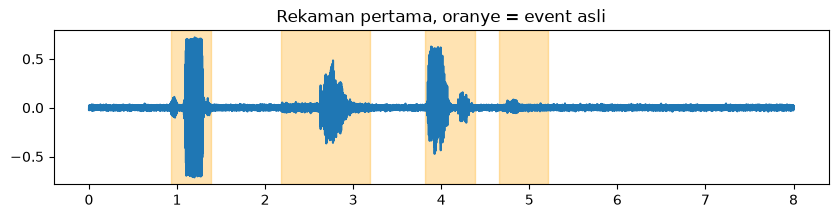

In [4]:
events_per_recording = annotations.groupby("path").size()
print(events_per_recording.value_counts())
durations = annotations["offset"] - annotations["onset"]
print(durations.describe().round(3))
print(annotations["label"].value_counts())

example_audio, _ = librosa.load(f"{DATA_FOLDER}/{all_recordings[0]}", sr=SAMPLE_RATE)
plt.figure(figsize=(10, 2))
plt.plot(np.arange(len(example_audio)) / SAMPLE_RATE, example_audio)
example_events = annotations[annotations["path"] == all_recordings[0]]
for _, event in example_events.iterrows():
    plt.axvspan(event["onset"], event["offset"], color="orange", alpha=0.3)
plt.title("Rekaman pertama, oranye = event asli")
plt.show()

## Langkah 1a — cari bagian yang lebih keras dari derau
Energi (RMS) dihitung tiap 10 ms. Potongan mulai saat energi naik melewati batas dan selesai
saat energi turun lagi.

In [5]:
def find_segments(audio):
    energy = librosa.feature.rms(y=audio, frame_length=1024, hop_length=HOP_LENGTH)[0]
    threshold = ENERGY_FACTOR * np.median(energy)
    frame_seconds = HOP_LENGTH / SAMPLE_RATE
    segments = []
    start = None
    for frame in range(len(energy)):
        if energy[frame] > threshold and start is None:
            start = frame * frame_seconds                     # suara mulai
        if energy[frame] <= threshold and start is not None:
            segments.append([start, frame * frame_seconds])   # suara selesai
            start = None
    if start is not None:
        segments.append([start, len(energy) * frame_seconds])
    return segments


# coba pada rekaman pertama
print(find_segments(example_audio)[:10])

[[0.91, 1.03], [1.05, 1.41], [2.17, 3.21], [3.81, 4.14], [4.16, 4.37], [4.72, 4.91]]


## Langkah 1b — gabung potongan yang berdekatan, buang yang terlalu pendek

In [6]:
def merge_segments(segments):
    merged = []
    for start, end in segments:
        if len(merged) > 0 and start - merged[-1][1] < MAX_GAP:
            merged[-1][1] = end           # jeda pendek: sambung ke potongan sebelumnya
        else:
            merged.append([start, end])
    kept = []
    for start, end in merged:
        if end - start >= MIN_DURATION:
            kept.append([start, end])
    return kept


# coba pada rekaman pertama, bandingkan dengan event asli
print(merge_segments(find_segments(example_audio)))
print(example_events[["onset", "offset", "label"]])

[[0.91, 1.41], [2.17, 3.21], [3.81, 4.37], [4.72, 4.91]]
   onset  offset  label
0  0.937   1.385   stop
1  2.186   3.186     go
2  3.811   4.387  right
3  4.661   5.213   left


## Langkah 1c — potong semua rekaman
Hasil: tabel (path, onset, offset) + daftar potongan suara untuk diklasifikasi.

In [7]:
def cut_recordings(paths):
    rows = []
    pieces = []
    for path in paths:
        audio, _ = librosa.load(f"{DATA_FOLDER}/{path}", sr=SAMPLE_RATE)
        for start, end in merge_segments(find_segments(audio)):
            rows.append([path, round(start, 3), round(end, 3)])
            pieces.append(audio[int(start * SAMPLE_RATE):int(end * SAMPLE_RATE)])
    table = pd.DataFrame(rows, columns=["path", "onset", "offset"])
    return table, pieces


val_segments, val_pieces = cut_recordings(val_recordings)
val_truth = annotations[annotations["path"].isin(val_recordings)]
print("potongan validasi:", len(val_segments), "| event asli:", len(val_truth))

potongan validasi: 129 | event asli: 129


## Langkah 2a — embedding wav2vec2
Potongan diletakkan di tengah klip 1 detik (sisanya nol), sama seperti klip train.

In [8]:
feature_extractor = AutoFeatureExtractor.from_pretrained(PRETRAINED_FOLDER, local_files_only=True)
encoder = Wav2Vec2Model.from_pretrained(PRETRAINED_FOLDER, local_files_only=True)
encoder.eval()
encoder = encoder.to(DEVICE)


def center_clip(audio):
    left = max(0, (CLIP_LENGTH - len(audio)) // 2)    # jumlah nol di kiri
    audio = np.pad(audio, (left, CLIP_LENGTH))
    return audio[:CLIP_LENGTH]


def extract_embeddings(pieces):
    batches = []
    for start in range(0, len(pieces), BATCH_SIZE):
        clips = []
        for piece in pieces[start:start + BATCH_SIZE]:
            clips.append(center_clip(piece))
        inputs = feature_extractor(clips, sampling_rate=SAMPLE_RATE, return_tensors="pt")
        with torch.no_grad():
            output = encoder(inputs.input_values.to(DEVICE), output_hidden_states=True)
        mean_over_time = output.hidden_states[LAYER].mean(dim=1)
        batches.append(mean_over_time.cpu().numpy())
    return np.concatenate(batches)


# coba pada 2 potongan
print("ukuran embedding 2 potongan:", extract_embeddings(val_pieces[:2]).shape)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: Z:/GEMASTIK-DATABASE/pretrained/wav2vec2_base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.weight           | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ukuran embedding 2 potongan: (2, 768)


## Langkah 2b — feature klip train (hening di awal-akhir dibuang) dan potongan validasi

In [9]:
train_pieces = []
for path in clip_train["path"]:
    audio, _ = librosa.load(f"{CLIP_FOLDER}/{path}", sr=SAMPLE_RATE)
    audio, _ = librosa.effects.trim(audio, top_db=25)
    train_pieces.append(audio)
X_train = extract_embeddings(train_pieces)
y_train = clip_train["label"]
X_val = extract_embeddings(val_pieces)
print(X_train.shape, X_val.shape)

(1200, 768) (129, 768)


## Langkah 2c — model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.
Model harus punya `predict_proba` (dipakai untuk membuang potongan yang tidak yakin).

In [10]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000))
# model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))
# model = make_pipeline(StandardScaler(), SVC(C=10, probability=True, random_state=SEED))

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](8,)","['down','go','left',...,'stop','up','yes']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,768
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## Langkah 3 — F1 event di validasi
Tiap event asli dicocokkan dengan satu potongan tebakan (onset dekat, label sama).
Satu potongan hanya boleh dipakai sekali. "Deteksi saja" = label tidak dicek.

In [11]:
def event_scores(predicted, truth, check_label):
    hits = 0
    for path in truth["path"].unique():
        candidates = predicted[predicted["path"] == path]
        unused = list(candidates.index)
        for _, event in truth[truth["path"] == path].iterrows():
            for row in unused:
                close = abs(candidates.loc[row, "onset"] - event["onset"]) <= TOLERANCE
                same_label = candidates.loc[row, "label"] == event["label"]
                if not check_label:
                    same_label = True
                if close and same_label:
                    unused.remove(row)
                    hits += 1
                    break
    precision = hits / len(predicted)
    recall = hits / len(truth)
    f1 = 2 * precision * recall / (precision + recall)
    return round(precision, 4), round(recall, 4), round(f1, 4)


probabilities = model.predict_proba(X_val)
val_segments["label"] = model.classes_[probabilities.argmax(axis=1)]
val_segments = val_segments[probabilities.max(axis=1) >= MIN_PROBABILITY]
print("presisi, recall, F1 (deteksi saja):", event_scores(val_segments, val_truth, False))
print("presisi, recall, F1 event (+label):", event_scores(val_segments, val_truth, True))
val_segments.head(8)

presisi, recall, F1 (deteksi saja): (0.907, 0.907, 0.907)
presisi, recall, F1 event (+label): (0.7209, 0.7209, 0.7209)


,path,onset,offset,label
0,klip/klip000.wav,0.91,1.41,stop
1,klip/klip000.wav,2.17,3.21,go
2,klip/klip000.wav,3.81,4.37,right
3,klip/klip000.wav,4.72,4.91,up
4,klip/klip001.wav,0.76,1.25,stop
5,klip/klip001.wav,2.13,2.51,right
6,klip/klip001.wav,3.51,3.83,right
7,klip/klip002.wav,0.70,1.77,down


## Prediksi rekaman test + submission (satu baris per event)

In [12]:
test_segments, test_pieces = cut_recordings(test_recordings)
probabilities = model.predict_proba(extract_embeddings(test_pieces))
confident = probabilities.max(axis=1) >= MIN_PROBABILITY
predictions = model.classes_[probabilities.argmax(axis=1)]

submission = pd.DataFrame()
submission["path"] = test_segments["path"][confident]
submission["onset"] = test_segments["onset"][confident]
submission["offset"] = test_segments["offset"][confident]
submission["label"] = predictions[confident]
submission.to_csv("submission.csv", index=False)
submission.head()

,path,onset,offset,label
0,klip/klip040.wav,0.90,1.31,yes
1,klip/klip040.wav,1.98,2.21,yes
2,klip/klip040.wav,3.20,3.54,no
3,klip/klip041.wav,1.54,1.72,yes
4,klip/klip041.wav,2.93,3.51,left


## Cek dengan kunci jawaban (HAPUS saat lomba)
Anotasi rekaman test hanya ada di data demo.

In [13]:
test_truth = annotations[annotations["path"].isin(test_recordings)]
print("presisi, recall, F1 event test:", event_scores(submission, test_truth, True))

presisi, recall, F1 event test: (0.6579, 0.641, 0.6494)
